# Pipeline de Tratamento e Agrupamento de Imagens de Retina

Este notebook implementa o pipeline prático utilizado para preparar imagens de fundo de olho, extrair características por meio de uma rede neural convolucional e realizar agrupamento não supervisionado.

O fluxo geral utilizado é:

1. Carregamento das imagens;
2. Pré-processamento;
3. Aplicação de CLAHE no canal de luminância;
4. Redimensionamento com preservação da proporção e padding;
5. Extração de características por meio da penúltima camada de uma rede neural;
6. Geração dos embeddings;
7. Redução de dimensionalidade com PCA;
8. Definição do número de clusters;
9. Agrupamento com K-Means;
10. Análise estatística e visual dos clusters encontrados.

## Escopo dos dados

Este pipeline utiliza exclusivamente os dados de treinamento do APTOS 2019.

São utilizados:

- `train.csv`, contendo os rótulos das imagens de treinamento;
- `train_images/`, contendo as imagens correspondentes.

Os arquivos `test.csv`, `test_images/` e `sample_submission.csv` não são utilizados neste experimento.

Os rótulos presentes em `train.csv` não serão utilizados durante a formação dos clusters. Eles serão empregados apenas posteriormente para caracterizar e interpretar os grupos encontrados pelo K-Means.

In [2]:
# Realiza importações de bibliotecas necessárias para o processamento de imagens e manipulação de dados.
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

In [3]:
# Localiza o diretório principal do projeto, verificando a existência de subdiretórios específicos.
def find_project_root(start_dir=None):
    start_dir = (
        start_dir
        or Path.cwd()
    ).resolve()

    for candidate in [
        start_dir,
        *start_dir.parents
    ]:
        if (
            (candidate / "01.Originais").exists()
            and
            (candidate / "04.Notebooks").exists()
        ):
            return candidate

    raise FileNotFoundError(
        "Diretório principal do projeto não encontrado."
    )


BASE_DIR = find_project_root()

print("Diretório principal:")
print(BASE_DIR)

Diretório principal:
C:\Users\d4rki\Desktop\Pesquisa\OIO+\DATASET_RETINA


In [4]:
# Diretório principal do APTOS;
APTOS_DIR = (
    BASE_DIR
    / "01.Originais"
    / "DR (Retinopatia Diabética)"
    / "APTOS-2019"
)

# Utiliza exclusivamente o conjunto de treino;
APTOS_TRAIN_CSV = (
    APTOS_DIR
    / "train.csv"
)

APTOS_TRAIN_IMAGES_DIR = (
    APTOS_DIR
    / "train_images"
)

print("CSV de treino:")
print(APTOS_TRAIN_CSV)

print(
    "\nExiste:",
    APTOS_TRAIN_CSV.exists()
)

print("\nDiretório de imagens de treino:")
print(APTOS_TRAIN_IMAGES_DIR)

print(
    "\nExiste:",
    APTOS_TRAIN_IMAGES_DIR.exists()
)

CSV de treino:
C:\Users\d4rki\Desktop\Pesquisa\OIO+\DATASET_RETINA\01.Originais\DR (Retinopatia Diabética)\APTOS-2019\train.csv

Existe: True

Diretório de imagens de treino:
C:\Users\d4rki\Desktop\Pesquisa\OIO+\DATASET_RETINA\01.Originais\DR (Retinopatia Diabética)\APTOS-2019\train_images

Existe: True


In [5]:
aptos_train = pd.read_csv(
    APTOS_TRAIN_CSV
)

print(
    "Registros de treino:",
    len(aptos_train)
)

aptos_train.head()

Registros de treino: 3662


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


In [6]:
quantidade_imagens_treino = len(
    list(
        APTOS_TRAIN_IMAGES_DIR.glob(
            "*.png"
        )
    )
)

print(
    "Registros no train.csv:",
    len(aptos_train)
)

print(
    "Imagens em train_images:",
    quantidade_imagens_treino
)

Registros no train.csv: 3662
Imagens em train_images: 3662


In [7]:
# Trata uma imagem do APTOS;
def tratar_imagem(
    caminho_imagem,
    tamanho_alvo=(224, 224),
    clip_limit=2.0,
    tile_grid_size=(8, 8),
    cor_padding=(0, 0, 0)
):
    # Abre a imagem e garante RGB;
    imagem = Image.open(
        caminho_imagem
    ).convert("RGB")

    imagem_rgb = np.array(
        imagem
    )

    # Converte RGB para LAB;
    imagem_lab = cv2.cvtColor(
        imagem_rgb,
        cv2.COLOR_RGB2LAB
    )

    # Separa os canais;
    canal_l, canal_a, canal_b = cv2.split(
        imagem_lab
    )

    # Aplica CLAHE apenas na luminância;
    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=tile_grid_size
    )

    canal_l_clahe = clahe.apply(
        canal_l
    )

    # Reconstrói LAB;
    imagem_lab_clahe = cv2.merge(
        (
            canal_l_clahe,
            canal_a,
            canal_b
        )
    )

    # Retorna para RGB;
    imagem_rgb_clahe = cv2.cvtColor(
        imagem_lab_clahe,
        cv2.COLOR_LAB2RGB
    )

    # Dimensões atuais;
    altura, largura = imagem_rgb_clahe.shape[:2]

    largura_alvo, altura_alvo = tamanho_alvo

    # Calcula a escala mantendo a proporção;
    escala = min(
        largura_alvo / largura,
        altura_alvo / altura
    )

    nova_largura = int(
        round(largura * escala)
    )

    nova_altura = int(
        round(altura * escala)
    )

    # Redimensiona sem deformar;
    imagem_redimensionada = cv2.resize(
        imagem_rgb_clahe,
        (
            nova_largura,
            nova_altura
        ),
        interpolation=cv2.INTER_AREA
    )

    # Calcula o padding;
    padding_horizontal = (
        largura_alvo - nova_largura
    )

    padding_vertical = (
        altura_alvo - nova_altura
    )

    topo = padding_vertical // 2
    baixo = padding_vertical - topo

    esquerda = padding_horizontal // 2
    direita = padding_horizontal - esquerda

    # Completa a imagem até 224 x 224;
    imagem_final = cv2.copyMakeBorder(
        imagem_redimensionada,
        topo,
        baixo,
        esquerda,
        direita,
        cv2.BORDER_CONSTANT,
        value=cor_padding
    )

    return imagem_final

## Validação do pré-processamento

Antes da extração de características, o pipeline de pré-processamento é aplicado às 3.662 imagens do conjunto de treinamento do APTOS 2019.

Nesta etapa, verifica-se se todas as imagens podem ser processadas corretamente e se o resultado final apresenta a dimensão esperada de 224 × 224 pixels com três canais RGB.

In [8]:
# Verifica se todas as imagens de treino podem ser tratadas corretamente;
erros_tratamento = []
dimensoes_invalidas = []

total_imagens = len(aptos_train)

for indice, registro in aptos_train.iterrows():

    id_imagem = registro["id_code"]

    caminho_imagem = (
        APTOS_TRAIN_IMAGES_DIR
        / f"{id_imagem}.png"
    )

    try:
        imagem_tratada = tratar_imagem(
            caminho_imagem
        )

        if imagem_tratada.shape != (224, 224, 3):
            dimensoes_invalidas.append({
                "id_imagem": id_imagem,
                "dimensao": imagem_tratada.shape
            })

    except Exception as erro:
        erros_tratamento.append({
            "id_imagem": id_imagem,
            "erro": str(erro)
        })

    # Mostra o progresso a cada 500 imagens;
    if (indice + 1) % 500 == 0:
        print(
            f"{indice + 1}/{total_imagens} imagens verificadas"
        )


print("\nVerificação concluída.")

print(
    "Total de imagens:",
    total_imagens
)

print(
    "Erros de processamento:",
    len(erros_tratamento)
)

print(
    "Dimensões inválidas:",
    len(dimensoes_invalidas)
)

500/3662 imagens verificadas
1000/3662 imagens verificadas
1500/3662 imagens verificadas
2000/3662 imagens verificadas
2500/3662 imagens verificadas
3000/3662 imagens verificadas
3500/3662 imagens verificadas

Verificação concluída.
Total de imagens: 3662
Erros de processamento: 0
Dimensões inválidas: 0


## Teste do pipeline em uma imagem

Antes do processamento completo do conjunto de treinamento, o pipeline é testado em uma única imagem do APTOS 2019.

Essa etapa tem como objetivo verificar individualmente o pré-processamento, a normalização, a preparação do tensor e, posteriormente, a extração do embedding pela EfficientNet-B1.

A imagem utilizada nesta seção serve apenas para validação do funcionamento do pipeline. O processamento utilizado na análise será posteriormente realizado sobre todas as 3.662 imagens do conjunto de treinamento.

ID: 000c1434d8d7
Dimensão final: (224, 224, 3)


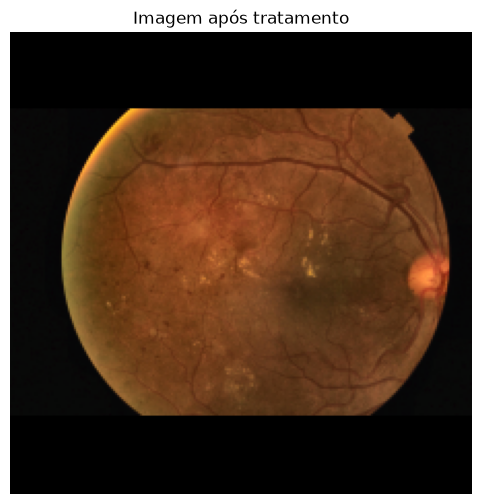

In [9]:
# Seleciona a primeira imagem do conjunto de treino;
id_exemplo = aptos_train.iloc[0]["id_code"]

caminho_exemplo = (
    APTOS_TRAIN_IMAGES_DIR
    / f"{id_exemplo}.png"
)

# Aplica o tratamento;
imagem_exemplo_tratada = tratar_imagem(
    caminho_exemplo
)

print("ID:", id_exemplo)

print(
    "Dimensão final:",
    imagem_exemplo_tratada.shape
)

plt.figure(figsize=(6, 6))

plt.imshow(
    imagem_exemplo_tratada
)

plt.title(
    "Imagem após tratamento"
)

plt.axis("off")

plt.show()

### Verificação visual do tratamento

A comparação permite observar o efeito conjunto das etapas de pré-processamento aplicadas à imagem.

Na imagem tratada, o CLAHE aumenta o contraste local da retina, enquanto o redimensionamento preserva a proporção original da fotografia. O espaço restante é preenchido com padding preto até atingir a dimensão final de 224 × 224 pixels.

O uso de padding evita a deformação das estruturas retinais que ocorreria caso a imagem fosse redimensionada diretamente para um formato quadrado.

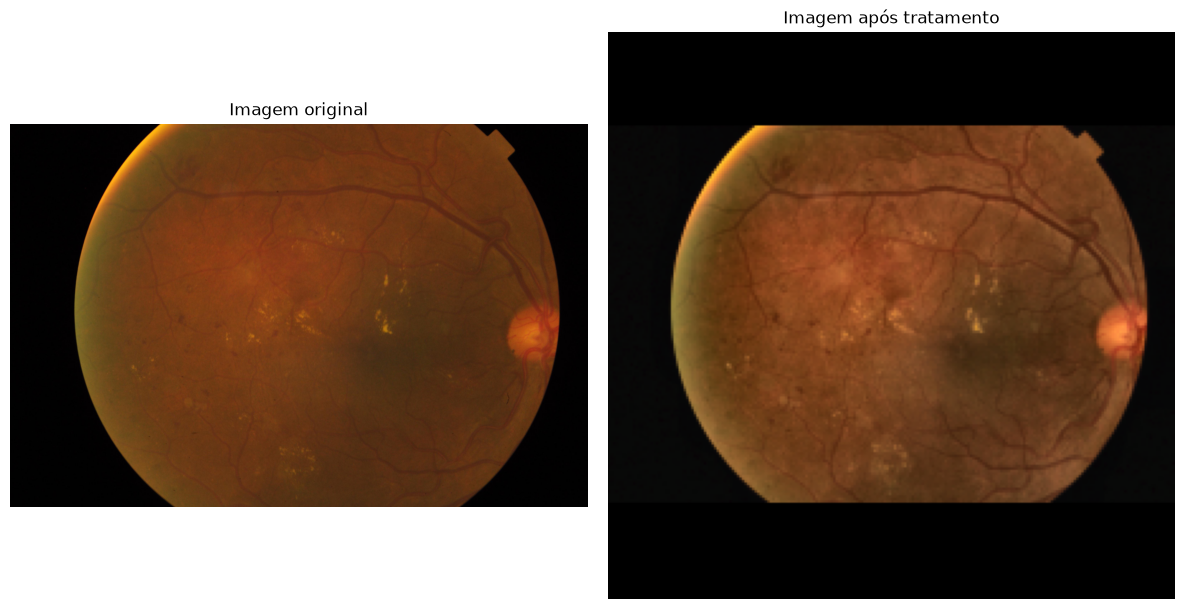

In [10]:
# Carrega a imagem original;
imagem_original = np.array(
    Image.open(
        caminho_exemplo
    ).convert("RGB")
)

# Compara a imagem original com a imagem tratada;
fig, eixos = plt.subplots(
    1,
    2,
    figsize=(12, 6)
)

eixos[0].imshow(
    imagem_original
)

eixos[0].set_title(
    "Imagem original"
)

eixos[1].imshow(
    imagem_exemplo_tratada
)

eixos[1].set_title(
    "Imagem após tratamento"
)

for eixo in eixos:
    eixo.axis("off")

plt.tight_layout()
plt.show()

In [11]:
# Importações necessárias para o uso do PyTorch e transformações de imagens.
import torch
from torchvision import transforms

In [12]:
# Verifica a versão do PyTorch, a versão do CUDA e se o CUDA está disponível.
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

PyTorch: 2.15.0+cu132
CUDA: 13.2
CUDA disponível: True
GPU: NVIDIA GeForce GTX 1660 Ti


In [13]:
# Define o dispositivo de processamento;
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Dispositivo:", device)

Dispositivo: cuda


In [14]:
# Transforma a imagem em tensor e aplica
# a normalização do ImageNet;

transformacao_efficientnet = transforms.Compose([
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [15]:
# Converte a imagem tratada para tensor normalizado;
imagem_tensor = transformacao_efficientnet(
    imagem_exemplo_tratada
)

print(
    "Dimensão:",
    imagem_tensor.shape
)

print(
    "Tipo:",
    imagem_tensor.dtype
)

print(
    "Valor mínimo:",
    imagem_tensor.min().item()
)

print(
    "Valor máximo:",
    imagem_tensor.max().item()
)

Dimensão: torch.Size([3, 224, 224])
Tipo: torch.float32
Valor mínimo: -2.1179039478302
Valor máximo: 2.248908281326294


In [16]:
# Adiciona a dimensão do lote e envia para a GPU;
imagem_tensor = (
    imagem_tensor
    .unsqueeze(0)
    .to(device)
)

print(
    "Dimensão para a rede:",
    imagem_tensor.shape
)

print(
    "Dispositivo:",
    imagem_tensor.device
)

Dimensão para a rede: torch.Size([1, 3, 224, 224])
Dispositivo: cuda:0


In [17]:
# Importações necessárias para carregar o modelo EfficientNet-B1 pré-treinado.
from torchvision.models import (
    efficientnet_b1,
    EfficientNet_B1_Weights
)

# Carrega os pesos pré-treinados;
pesos = EfficientNet_B1_Weights.DEFAULT

# Carrega a EfficientNet-B1;
modelo = efficientnet_b1(
    weights=pesos
)

# Remove a camada final de classificação;
modelo.classifier = torch.nn.Identity()

# Envia o modelo para a GPU;
modelo = modelo.to(device)

# Coloca o modelo em modo de avaliação;
modelo.eval()

print(
    "Camada final:",
    modelo.classifier
)

Camada final: Identity()


In [18]:
# Extrai o embedding da imagem de teste;
with torch.no_grad():
    embedding_exemplo = modelo(
        imagem_tensor
    )

print(
    "Dimensão do embedding:",
    embedding_exemplo.shape
)

print(
    "Dispositivo:",
    embedding_exemplo.device
)

Dimensão do embedding: torch.Size([1, 1280])
Dispositivo: cuda:0


## Processamento completo do conjunto de treino

Após a validação do pipeline em uma única imagem, o mesmo processo é aplicado ao conjunto completo de treinamento do APTOS 2019.

Cada imagem será pré-processada, normalizada e enviada à EfficientNet-B1 para extração de um embedding com 1280 características.

O processamento será realizado em lotes, permitindo utilizar a GPU de forma mais eficiente sem carregar todas as imagens simultaneamente na memória.

In [19]:
# Define o processamento de cada imagem do APTOS antes de ela ser organizada em lotes pelo DataLoader.
from torch.utils.data import Dataset

class AptosDataset(Dataset):

    def __init__(
        self,
        dataframe,
        diretorio_imagens,
        transformacao
    ):
        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.diretorio_imagens = diretorio_imagens
        self.transformacao = transformacao


    def __len__(self):
        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        indice
    ):
        id_imagem = (
            self.dataframe
            .iloc[indice]["id_code"]
        )

        caminho_imagem = (
            self.diretorio_imagens
            / f"{id_imagem}.png"
        )

        imagem_tratada = tratar_imagem(
            caminho_imagem
        )

        imagem_tensor = self.transformacao(
            imagem_tratada
        )

        return (
            imagem_tensor,
            id_imagem
        )

In [20]:
# Cria o dataset do APTOS com as transformações definidas.
dataset_aptos = AptosDataset(
    dataframe=aptos_train,
    diretorio_imagens=APTOS_TRAIN_IMAGES_DIR,
    transformacao=transformacao_efficientnet
)

print(
    "Quantidade de imagens no Dataset:",
    len(dataset_aptos)
)

Quantidade de imagens no Dataset: 3662


In [21]:
# Seleciona a primeira imagem do dataset para teste;
imagem_teste, id_teste = dataset_aptos[0]

print("ID:", id_teste)
print("Dimensão:", imagem_teste.shape)
print("Tipo:", imagem_teste.dtype)

ID: 000c1434d8d7
Dimensão: torch.Size([3, 224, 224])
Tipo: torch.float32


In [22]:
# Cria o DataLoader para organizar as imagens em lotes.
from torch.utils.data import DataLoader

dataloader_aptos = DataLoader(
    dataset_aptos,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print(
    "Quantidade de lotes:",
    len(dataloader_aptos)
)

Quantidade de lotes: 115


In [23]:
# Testa o DataLoader, obtendo o primeiro lote de imagens e IDs.
imagens_lote, ids_lote = next(
    iter(dataloader_aptos)
)

print(
    "Dimensão do lote:",
    imagens_lote.shape
)

print(
    "Quantidade de IDs:",
    len(ids_lote)
)

print(
    "Primeiro ID:",
    ids_lote[0]
)

Dimensão do lote: torch.Size([32, 3, 224, 224])
Quantidade de IDs: 32
Primeiro ID: 000c1434d8d7


In [24]:
# Envia o primeiro lote para a GPU;
imagens_lote = imagens_lote.to(
    device,
    non_blocking=True
)

print(
    "Dispositivo do lote:",
    imagens_lote.device
)

Dispositivo do lote: cuda:0


In [25]:
# Extrai os embeddings do primeiro lote;
with torch.no_grad():
    embeddings_lote = modelo(
        imagens_lote
    )

print(
    "Dimensão dos embeddings:",
    embeddings_lote.shape
)

print(
    "Dispositivo:",
    embeddings_lote.device
)

Dimensão dos embeddings: torch.Size([32, 1280])
Dispositivo: cuda:0


In [26]:
# Extrai os embeddings de todas as imagens do conjunto de treino;
todos_embeddings = []
todos_ids = []

total_lotes = len(dataloader_aptos)

modelo.eval()

with torch.no_grad():

    for numero_lote, (
        imagens_lote,
        ids_lote
    ) in enumerate(
        dataloader_aptos,
        start=1
    ):

        # Envia as imagens para a GPU;
        imagens_lote = imagens_lote.to(
            device,
            non_blocking=True
        )

        # Extrai as características;
        embeddings_lote = modelo(
            imagens_lote
        )

        # Move os embeddings para a CPU;
        todos_embeddings.append(
            embeddings_lote.cpu()
        )

        # Guarda os IDs correspondentes;
        todos_ids.extend(
            ids_lote
        )

        # Exibe o progresso;
        if (
            numero_lote % 20 == 0
            or numero_lote == total_lotes
        ):
            print(
                f"Lote {numero_lote}/{total_lotes}"
            )

Lote 20/115
Lote 40/115
Lote 60/115
Lote 80/115
Lote 100/115
Lote 115/115


In [27]:
# Junta os embeddings de todos os lotes em uma única matriz;
embeddings_aptos = torch.cat(
    todos_embeddings,
    dim=0
)

print(
    "Dimensão final dos embeddings:",
    embeddings_aptos.shape
)

print(
    "Quantidade de IDs:",
    len(todos_ids)
)

Dimensão final dos embeddings: torch.Size([3662, 1280])
Quantidade de IDs: 3662


In [28]:
# Verifica a integridade da matriz de embeddings;
print(
    "Dimensão:",
    embeddings_aptos.shape
)

print(
    "Tipo:",
    embeddings_aptos.dtype
)

print(
    "Valores NaN:",
    torch.isnan(
        embeddings_aptos
    ).sum().item()
)

print(
    "Valores infinitos:",
    torch.isinf(
        embeddings_aptos
    ).sum().item()
)

Dimensão: torch.Size([3662, 1280])
Tipo: torch.float32
Valores NaN: 0
Valores infinitos: 0


In [29]:
# Define o diretório onde os embeddings serão armazenados;
EMBEDDINGS_DIR = (
    BASE_DIR
    / "02.Catálogos"
    / "ANALISES"
    / "Embeddings"
)

EMBEDDINGS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Converte os embeddings para NumPy;
embeddings_numpy = embeddings_aptos.numpy()


# Salva a matriz de embeddings;
caminho_embeddings = (
    EMBEDDINGS_DIR
    / "aptos_train_embeddings.npy"
)

np.save(
    caminho_embeddings,
    embeddings_numpy
)


# Salva os IDs na mesma ordem dos embeddings;
caminho_ids = (
    EMBEDDINGS_DIR
    / "aptos_train_ids.csv"
)

pd.DataFrame({
    "id_code": todos_ids
}).to_csv(
    caminho_ids,
    index=False
)


print(
    "Embeddings salvos em:",
    caminho_embeddings
)

print(
    "IDs salvos em:",
    caminho_ids
)

Embeddings salvos em: C:\Users\d4rki\Desktop\Pesquisa\OIO+\DATASET_RETINA\02.Catálogos\ANALISES\Embeddings\aptos_train_embeddings.npy
IDs salvos em: C:\Users\d4rki\Desktop\Pesquisa\OIO+\DATASET_RETINA\02.Catálogos\ANALISES\Embeddings\aptos_train_ids.csv


In [30]:
# Recarrega os embeddings e os IDs salvos;
embeddings_carregados = np.load(
    caminho_embeddings
)

ids_carregados = pd.read_csv(
    caminho_ids
)


print(
    "Dimensão dos embeddings:",
    embeddings_carregados.shape
)

print(
    "Quantidade de IDs:",
    len(ids_carregados)
)

print(
    "Primeiro ID:",
    ids_carregados.iloc[0]["id_code"]
)

Dimensão dos embeddings: (3662, 1280)
Quantidade de IDs: 3662
Primeiro ID: 000c1434d8d7


## Redução de dimensionalidade com PCA

Os embeddings extraídos pela EfficientNet-B1 possuem 1280 características por imagem. O PCA é utilizado para reduzir essa dimensionalidade, preservando as direções que concentram a maior variabilidade dos dados.

Inicialmente, o PCA é ajustado aos embeddings completos para analisar a variância explicada acumulada e auxiliar na escolha das quantidades de componentes que serão posteriormente comparadas no agrupamento com K-Means.

In [31]:
from sklearn.decomposition import PCA

# Ajusta o PCA aos embeddings completos;
pca_completo = PCA()

pca_completo.fit(
    embeddings_carregados
)

# Calcula a variância explicada acumulada;
variancia_acumulada = np.cumsum(
    pca_completo.explained_variance_ratio_
)

print(
    "Quantidade de componentes disponíveis:",
    len(variancia_acumulada)
)

Quantidade de componentes disponíveis: 1280


In [32]:
# Calcula quantos componentes são necessários
# para atingir diferentes níveis de variância explicada;

limiares_variancia = [
    0.80,
    0.90,
    0.95,
    0.99
]

for limiar in limiares_variancia:

    quantidade_componentes = (
        np.argmax(
            variancia_acumulada >= limiar
        )
        + 1
    )

    print(
        f"{limiar * 100:.0f}% da variância:",
        quantidade_componentes,
        "componentes"
    )

80% da variância: 56 componentes
90% da variância: 148 componentes
95% da variância: 295 componentes
99% da variância: 706 componentes


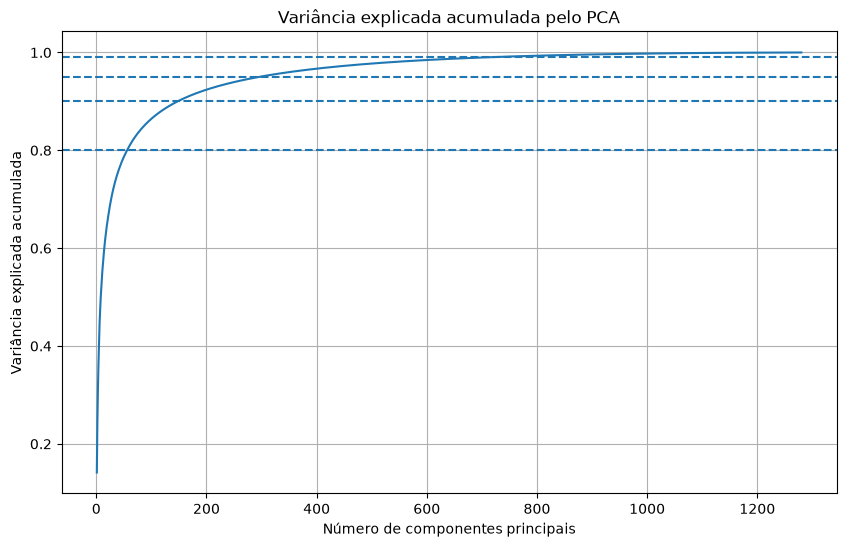

In [33]:
# Exibe a variância explicada acumulada pelo PCA;

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    range(
        1,
        len(variancia_acumulada) + 1
    ),
    variancia_acumulada
)

plt.axhline(
    y=0.80,
    linestyle="--"
)

plt.axhline(
    y=0.90,
    linestyle="--"
)

plt.axhline(
    y=0.95,
    linestyle="--"
)

plt.axhline(
    y=0.99,
    linestyle="--"
)

plt.xlabel(
    "Número de componentes principais"
)

plt.ylabel(
    "Variância explicada acumulada"
)

plt.title(
    "Variância explicada acumulada pelo PCA"
)

plt.grid()

plt.show()

In [34]:
# Transforma os embeddings para o espaço do PCA;
embeddings_pca_completo = pca_completo.transform(
    embeddings_carregados
)

# Define as quantidades de componentes que serão comparadas;

quantidades_componentes = [
    56,
    148,
    295,
    706
]

# Cria uma versão dos embeddings para cada quantidade de componentes;

embeddings_pca = {}

for quantidade in quantidades_componentes:

    embeddings_pca[quantidade] = (
        embeddings_pca_completo[
            :,
            :quantidade
        ]
    )

    print(
        f"PCA com {quantidade} componentes:",
        embeddings_pca[quantidade].shape
    )

PCA com 56 componentes: (3662, 56)
PCA com 148 componentes: (3662, 148)
PCA com 295 componentes: (3662, 295)
PCA com 706 componentes: (3662, 706)


## Definição do número de clusters

Para avaliar uma quantidade adequada de clusters, o algoritmo K-Means será executado com diferentes valores de `k` sobre cada uma das representações geradas pelo PCA.

Inicialmente, será utilizado o método do cotovelo, baseado na inércia do K-Means. A inércia representa a soma das distâncias quadráticas das amostras em relação ao centro do cluster ao qual pertencem.

A análise será realizada separadamente para as representações com 56, 148, 295 e 706 componentes principais.

In [35]:
from sklearn.cluster import KMeans

# Define os valores de k que serão avaliados;
valores_k = range(
    2,
    11
)

# Armazena as inércias de cada configuração de PCA;
inercias = {}

for quantidade in quantidades_componentes:

    inercias[quantidade] = []

    dados_pca = embeddings_pca[
        quantidade
    ]

    for k in valores_k:

        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        kmeans.fit(
            dados_pca
        )

        inercias[quantidade].append(
            kmeans.inertia_
        )

    print(
        f"PCA {quantidade}: concluído"
    )

PCA 56: concluído
PCA 148: concluído
PCA 295: concluído
PCA 706: concluído


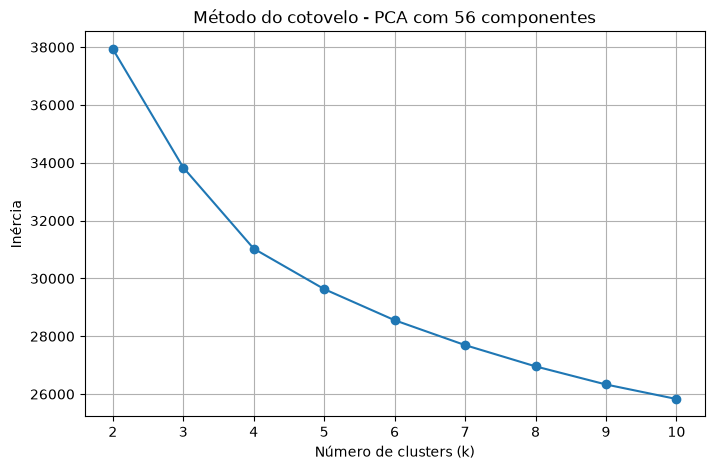

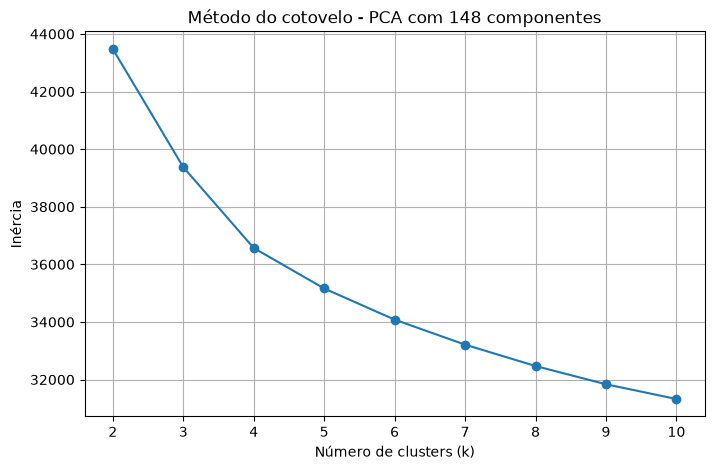

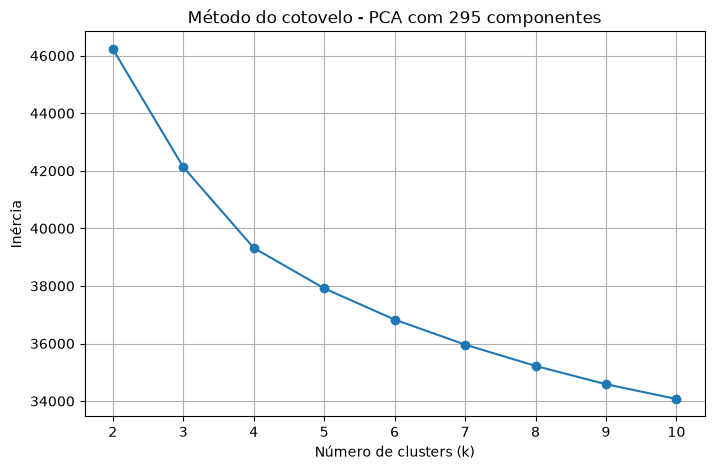

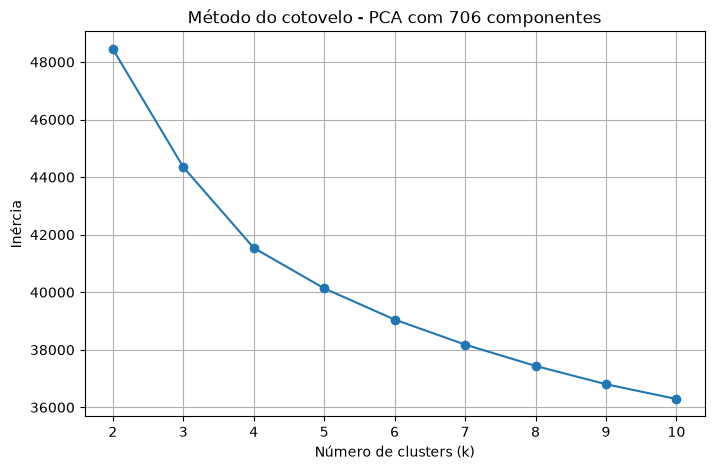

In [36]:
# Exibe a curva do método do cotovelo para cada quantidade de componentes do PCA;
for quantidade in quantidades_componentes:

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        list(valores_k),
        inercias[quantidade],
        marker="o"
    )

    plt.xlabel(
        "Número de clusters (k)"
    )

    plt.ylabel(
        "Inércia"
    )

    plt.title(
        f"Método do cotovelo - PCA com {quantidade} componentes"
    )

    plt.xticks(
        list(valores_k)
    )

    plt.grid()

    plt.show()

In [37]:
# Avalia a qualidade dos clusters utilizando a pontuação de silhueta para cada configuração de PCA e número de clusters.
from sklearn.metrics import silhouette_score

silhuetas = {}

for quantidade in quantidades_componentes:

    silhuetas[quantidade] = []

    dados_pca = embeddings_pca[
        quantidade
    ]

    for k in valores_k:

        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        rotulos = kmeans.fit_predict(
            dados_pca
        )

        pontuacao = silhouette_score(
            dados_pca,
            rotulos
        )

        silhuetas[quantidade].append(
            pontuacao
        )

    print(
        f"PCA {quantidade}: concluído"
    )

PCA 56: concluído
PCA 148: concluído
PCA 295: concluído
PCA 706: concluído


PCA 56: melhor k = 5 | Silhouette = 0.1753


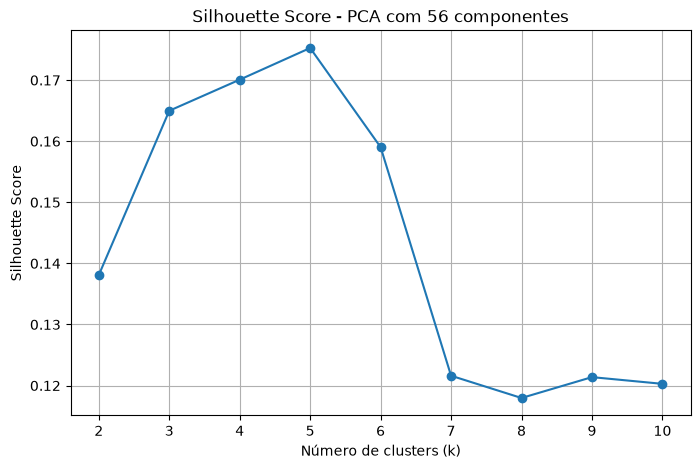

PCA 148: melhor k = 5 | Silhouette = 0.1537


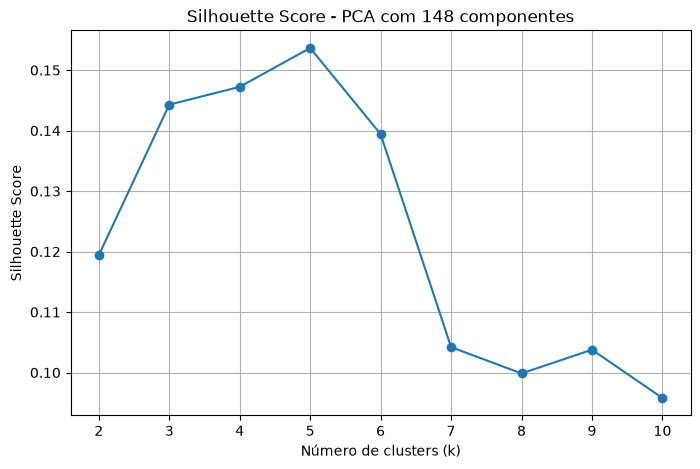

PCA 295: melhor k = 5 | Silhouette = 0.1443


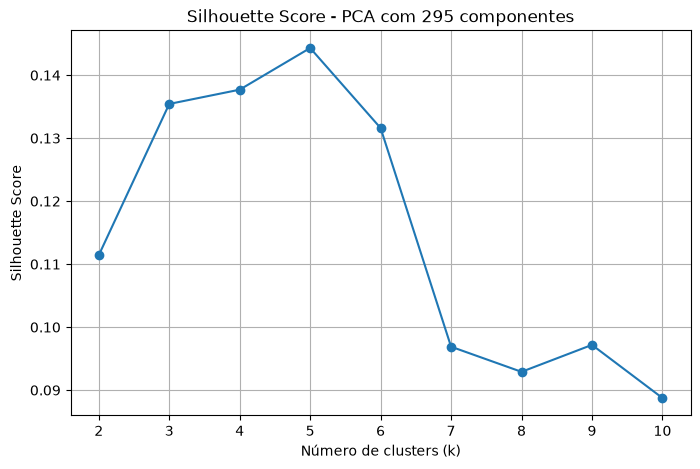

PCA 706: melhor k = 5 | Silhouette = 0.1374


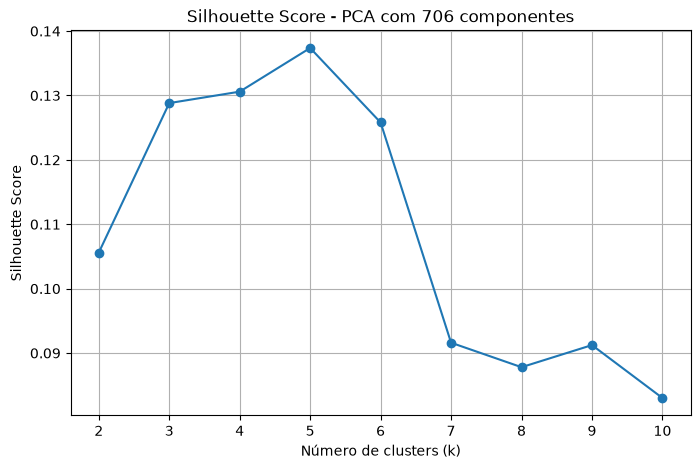

In [38]:
# Exibe a curva do Silhouette Score e identifica o melhor k para cada PCA;
for quantidade in quantidades_componentes:

    valores_silhueta = silhuetas[
        quantidade
    ]

    melhor_indice = np.argmax(
        valores_silhueta
    )

    melhor_k = list(valores_k)[
        melhor_indice
    ]

    melhor_silhueta = valores_silhueta[
        melhor_indice
    ]

    print(
        f"PCA {quantidade}: "
        f"melhor k = {melhor_k} | "
        f"Silhouette = {melhor_silhueta:.4f}"
    )

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        list(valores_k),
        valores_silhueta,
        marker="o"
    )

    plt.xlabel(
        "Número de clusters (k)"
    )

    plt.ylabel(
        "Silhouette Score"
    )

    plt.title(
        f"Silhouette Score - PCA com {quantidade} componentes"
    )

    plt.xticks(
        list(valores_k)
    )

    plt.grid()

    plt.show()

### Análise da quantidade de clusters

O método do cotovelo indicou uma mudança mais acentuada na redução da inércia aproximadamente entre quatro e cinco clusters nas diferentes representações geradas pelo PCA.

A análise pelo Silhouette Score apresentou um resultado mais consistente, indicando `k = 5` como a melhor configuração para todas as quantidades de componentes avaliadas.

Os maiores valores de Silhouette obtidos foram:

- 56 componentes: 0,1753;
- 148 componentes: 0,1537;
- 295 componentes: 0,1443;
- 706 componentes: 0,1374.

Entre as configurações avaliadas, a representação com 56 componentes e cinco clusters apresentou o maior Silhouette Score. Entretanto, os valores relativamente baixos indicam que os grupos encontrados possuem sobreposição e não apresentam separação fortemente definida.

## Agrupamento final com K-Means

Com base nas análises anteriores, utiliza-se a representação reduzida para 56 componentes principais e `k = 5` clusters.

O K-Means é aplicado sem utilizar os rótulos de diagnóstico. Cada imagem é associada ao cluster correspondente somente com base nas características extraídas pela EfficientNet-B1 e reduzidas pelo PCA.

In [39]:
# Seleciona a representação com 56 componentes;
dados_pca_final = embeddings_pca[
    56
]

# Executa o K-Means com 5 clusters;
kmeans_final = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20
)

clusters = kmeans_final.fit_predict(
    dados_pca_final
)

print(
    "Quantidade de imagens agrupadas:",
    len(clusters)
)

print(
    "Clusters encontrados:",
    np.unique(clusters)
)

Quantidade de imagens agrupadas: 3662
Clusters encontrados: [0 1 2 3 4]


In [40]:
# Associa cada ID ao cluster encontrado;
resultado_clusters = pd.DataFrame({
    "id_code": todos_ids,
    "cluster": clusters
})

print(
    "Quantidade de registros:",
    len(resultado_clusters)
)

resultado_clusters.head()

Quantidade de registros: 3662


,id_code,cluster
0,000c1434d8d7,2
1,001639a390f0,2
2,0024cdab0c1e,2
3,002c21358ce6,1
4,005b95c28852,4


In [41]:
# Conta a quantidade de imagens em cada cluster;
quantidade_por_cluster = (
    resultado_clusters["cluster"]
    .value_counts()
    .sort_index()
)

print(
    quantidade_por_cluster
)

cluster
0     318
1     960
2    1404
3     469
4     511
Name: count, dtype: int64


In [42]:
# Calcula a proporção de imagens em cada cluster;
percentual_por_cluster = (
    resultado_clusters["cluster"]
    .value_counts(
        normalize=True
    )
    .sort_index()
    * 100
)

print(
    percentual_por_cluster.round(2)
)

cluster
0     8.68
1    26.22
2    38.34
3    12.81
4    13.95
Name: proportion, dtype: float64


### Distribuição das imagens entre os clusters

O agrupamento resultou em cinco clusters com tamanhos diferentes. O cluster 2 apresentou a maior concentração de imagens, com 1.404 registros (38,34%), enquanto o cluster 0 apresentou a menor quantidade, com 318 imagens (8,68%).

Essa diferença indica que os grupos formados pelo K-Means não possuem distribuição uniforme, refletindo a organização das imagens de acordo com a similaridade das características extraídas pela EfficientNet-B1.

In [43]:
# Adiciona o diagnóstico apenas para análise posterior dos clusters;
resultado_clusters = resultado_clusters.merge(
    aptos_train[
        [
            "id_code",
            "diagnosis"
        ]
    ],
    on="id_code",
    how="left"
)

resultado_clusters.head()

,id_code,cluster,diagnosis
0,000c1434d8d7,2,2
1,001639a390f0,2,4
2,0024cdab0c1e,2,1
3,002c21358ce6,1,0
4,005b95c28852,4,0


In [44]:
# Conta os diagnósticos presentes em cada cluster;
distribuicao_diagnosticos = pd.crosstab(
    resultado_clusters["cluster"],
    resultado_clusters["diagnosis"]
)

print(
    distribuicao_diagnosticos
)

diagnosis    0    1    2    3    4
cluster                           
0          235   13   60    3    7
1          895   26   36    0    3
2           40  284  717  131  232
3          140   41  180   55   53
4          495    6    6    4    0


In [45]:
# Calcula a porcentagem de cada diagnóstico dentro de cada cluster;
percentual_diagnosticos = pd.crosstab(
    resultado_clusters["cluster"],
    resultado_clusters["diagnosis"],
    normalize="index"
) * 100

# Adiciona o total de imagens de cada cluster;
percentual_diagnosticos["total_imagens"] = (
    resultado_clusters["cluster"]
    .value_counts()
    .sort_index()
)

percentual_diagnosticos.round(2)

diagnosis,0,1,2,3,4,total_imagens
cluster,,,,,,
0,73.90,4.09,18.87,0.94,2.20,318
1,93.23,2.71,3.75,0.00,0.31,960
2,2.85,20.23,51.07,9.33,16.52,1404
3,29.85,8.74,38.38,11.73,11.30,469
4,96.87,1.17,1.17,0.78,0.00,511


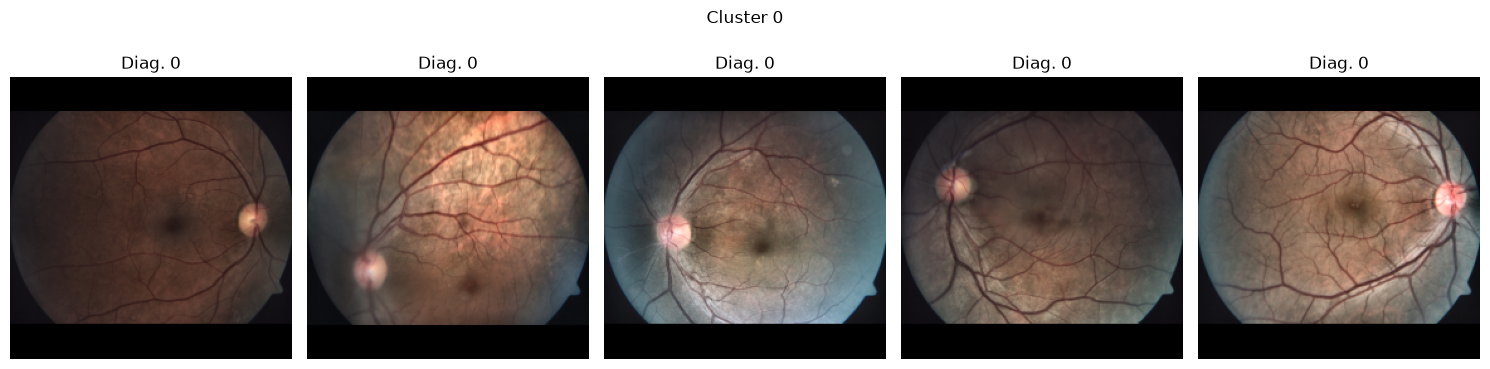

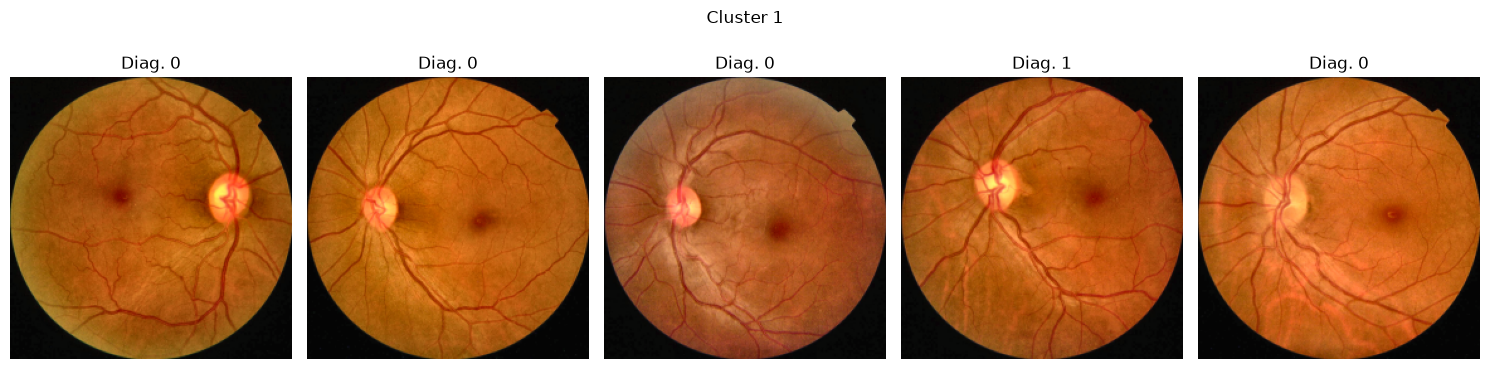

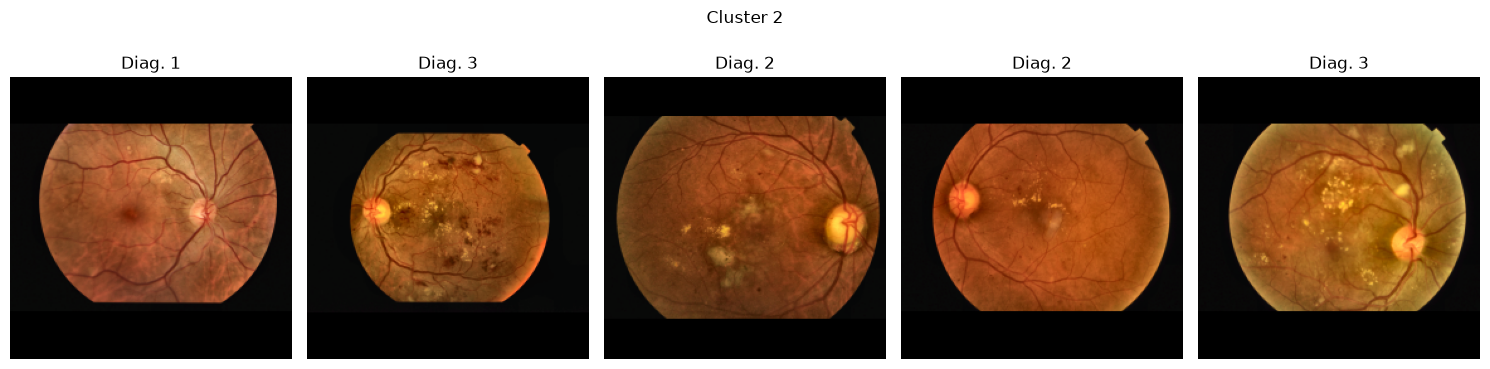

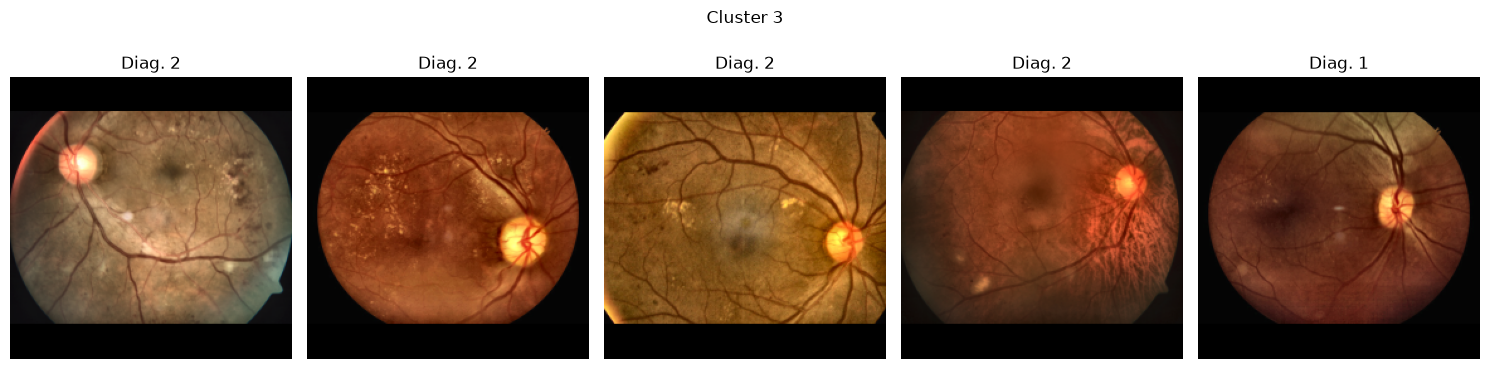

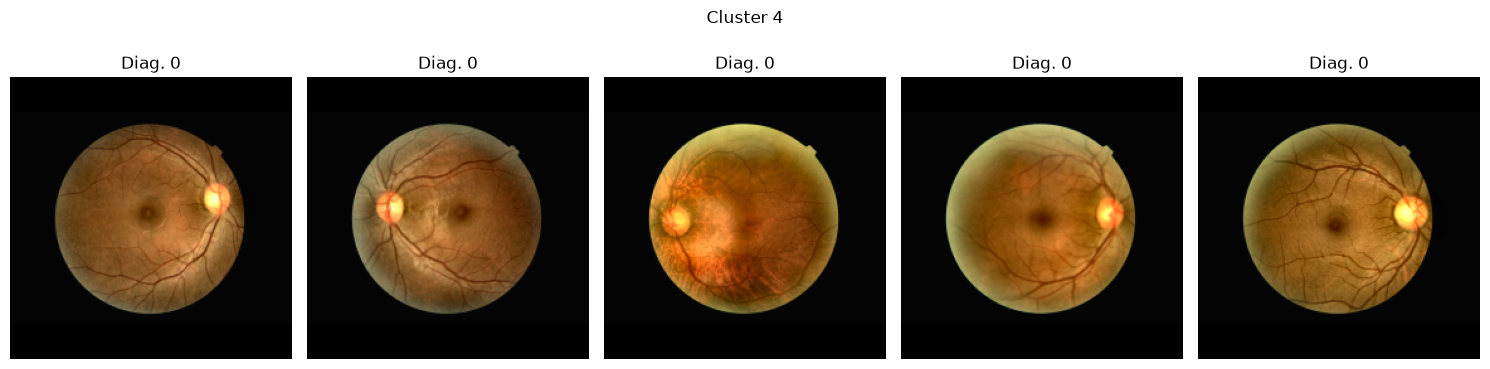

In [46]:
# Exibe algumas imagens de cada cluster;
quantidade_exemplos = 5

for cluster in sorted(
    resultado_clusters["cluster"].unique()
):

    exemplos = (
        resultado_clusters[
            resultado_clusters["cluster"] == cluster
        ]
        .sample(n=quantidade_exemplos, random_state=42)
    )

    fig, eixos = plt.subplots(
        1,
        quantidade_exemplos,
        figsize=(15, 4)
    )

    fig.suptitle(
        f"Cluster {cluster}"
    )

    for eixo, (_, registro) in zip(
        eixos,
        exemplos.iterrows()
    ):

        caminho_imagem = (
            APTOS_TRAIN_IMAGES_DIR
            / f"{registro['id_code']}.png"
        )

        imagem = tratar_imagem(
            caminho_imagem
        )

        eixo.imshow(imagem)

        eixo.set_title(
            f"Diag. {registro['diagnosis']}"
        )

        eixo.axis("off")

    plt.tight_layout()
    plt.show()

### Análise visual dos clusters

A inspeção das imagens tratadas mostra que os clusters formados pelo K-Means apresentam diferenças tanto relacionadas ao conteúdo das imagens quanto às características visuais de aquisição.

O cluster 0 apresenta predominantemente imagens mais escuras e com menor saturação, sendo composto majoritariamente por imagens de diagnóstico 0. O cluster 1 apresenta imagens mais claras e com tonalidade alaranjada relativamente uniforme, além de possuir forte predominância de imagens sem retinopatia diabética.

O cluster 2 concentra imagens com maior presença visual de alterações retinianas e apresenta predominância do diagnóstico 2, além de reunir uma parcela significativa dos diagnósticos 1, 3 e 4. O cluster 3 apresenta maior heterogeneidade visual e também maior diversidade entre os diagnósticos.

O cluster 4 é formado predominantemente por imagens de diagnóstico 0, mas apresenta características visuais diferentes das observadas no cluster 1, principalmente em relação ao enquadramento, ao tamanho aparente da retina e à área de fundo ao redor da imagem.

Esses resultados indicam que o agrupamento não reproduz diretamente as classes de diagnóstico. As características extraídas pela EfficientNet-B1 também representam diferenças de iluminação, coloração, enquadramento e campo de visão das imagens, além de possíveis características relacionadas às alterações retinianas.

In [47]:
# Salva o resultado final do agrupamento;
caminho_resultado_clusters = (
    BASE_DIR
    / "02.Catálogos"
    / "ANALISES"
    / "aptos_clusters_kmeans.csv"
)

resultado_clusters.to_csv(
    caminho_resultado_clusters,
    index=False
)

print(
    "Resultado salvo em:",
    caminho_resultado_clusters
)

Resultado salvo em: C:\Users\d4rki\Desktop\Pesquisa\OIO+\DATASET_RETINA\02.Catálogos\ANALISES\aptos_clusters_kmeans.csv


## Conclusão

O pipeline permitiu processar as 3.662 imagens de treinamento do APTOS 2019, aplicar o pré-processamento definido, extrair características com a EfficientNet-B1 e representar cada imagem por meio de embeddings de 1280 características.

A aplicação do PCA mostrou que 56 componentes principais preservam aproximadamente 80% da variância dos embeddings. A comparação entre diferentes dimensionalidades e valores de `k` indicou uma configuração adequada com 56 componentes e cinco clusters.

Os clusters apresentaram tamanhos e composições diferentes. A análise posterior utilizando os rótulos de diagnóstico mostrou que alguns grupos possuem forte concentração de determinadas classes, enquanto outros apresentam maior heterogeneidade. A inspeção visual também mostrou que o agrupamento considera não apenas possíveis alterações retinianas, mas também características como iluminação, coloração, enquadramento e campo de visão das imagens.

Os rótulos de diagnóstico não foram utilizados durante a formação dos clusters, sendo empregados apenas posteriormente para auxiliar na interpretação dos grupos encontrados.